# MobileNetV2 Daun Herbal — Resize 224×224, Tanpa Class Weight

Perubahan utama:
- split 70% training, 15% validation, 15% testing;
- resize fisik setiap citra menjadi 224×224;
- tanpa `class_weight`;
- augmentasi: horizontal flip, rotasi ±20°, translasi 20%, dan zoom 20%;
- pelatihan tahap 1 (feature extraction) dan tahap 2 (fine-tuning);
- evaluasi, confusion matrix, penyimpanan model, dan konversi TFLite Float32.

In [1]:
# 1. Import library
import os
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from tensorflow.keras.layers import Input, Dense, Dropout, GlobalAveragePooling2D, Rescaling
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.applications import MobileNetV2


In [2]:
# 2. Hubungkan Google Drive
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# 3. Konfigurasi
DATASET_PATH = "/content/drive/MyDrive/DATASET"

OUTPUT_SPLIT = (
    "/content/drive/MyDrive/"
    "DATASETSPLIT"
)

SAVE_DIR = (
    "/content/drive/MyDrive/"
    "skripsi_mobilenetv2"
)

IMG_SIZE = 224
INPUT_SHAPE = (IMG_SIZE, IMG_SIZE, 3)
BATCH_SIZE = 32
EPOCHS_TAHAP1 = 25
EPOCHS_TAHAP2 = 25
SEED = 42

VALID_EXTENSIONS = (
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
)

RESET_OUTPUT_SPLIT = True

os.makedirs(SAVE_DIR, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(f"Dataset tidak ditemukan: {DATASET_PATH}")

print("Dataset :", DATASET_PATH)
print("Output  :", OUTPUT_SPLIT)
print("Input   :", INPUT_SHAPE)

Dataset : /content/drive/MyDrive/DATASET
Output  : /content/drive/MyDrive/DATASETSPLIT
Input   : (224, 224, 3)


In [4]:
# ============================================================
# 4. MEMBACA PATH DAN LABEL DATASET
# ============================================================

def ambil_semua_citra(dataset_path):
    data = []

    class_folders = sorted([
        folder
        for folder in os.listdir(dataset_path)
        if os.path.isdir(
            os.path.join(dataset_path, folder)
        )
    ])

    if not class_folders:
        raise ValueError(
            "Folder kelas tidak ditemukan."
        )

    for class_name in class_folders:
        class_path = os.path.join(
            dataset_path,
            class_name
        )

        for root, _, files in os.walk(class_path):
            for filename in files:

                if not filename.lower().endswith(
                    VALID_EXTENSIONS
                ):
                    continue

                image_path = os.path.join(
                    root,
                    filename
                )

                data.append({
                    "image_path": image_path,
                    "label": class_name
                })

    return pd.DataFrame(data)


all_df = ambil_semua_citra(DATASET_PATH)

if all_df.empty:
    raise ValueError(
        "Tidak ditemukan citra pada dataset."
    )

class_names = sorted(
    all_df["label"].unique()
)

num_classes = len(class_names)

print("Jumlah kelas :", num_classes)
print("Total citra  :", len(all_df))
print("Nama kelas   :", class_names)

display(
    all_df["label"]
    .value_counts()
    .reindex(class_names)
    .rename("jumlah_citra")
    .to_frame()
)

Jumlah kelas : 10
Total citra  : 3740
Nama kelas   : ['Daun Jambu Biji', 'Daun Kari', 'Daun Kemangi', 'Daun Kunyit', 'Daun Mint', 'Daun Pepaya', 'Daun Sirih', 'Daun Sirsak', 'Lidah Buaya', 'Teh Hijau']


,jumlah_citra
label,
Daun Jambu Biji,450
Daun Kari,220
Daun Kemangi,450
Daun Kunyit,120
Daun Mint,260
Daun Pepaya,450
Daun Sirih,450
Daun Sirsak,450
Lidah Buaya,450


In [5]:
# 5. Split 70% training, 15% validation, 15% testing
train_source_df, temp_source_df = train_test_split(
    all_df,
    train_size=0.70,
    test_size=0.30,
    stratify=all_df["label"],
    random_state=SEED,
    shuffle=True
)

val_source_df, test_source_df = train_test_split(
    temp_source_df,
    train_size=0.50,
    test_size=0.50,
    stratify=temp_source_df["label"],
    random_state=SEED,
    shuffle=True
)

train_source_df = train_source_df.reset_index(drop=True)
val_source_df = val_source_df.reset_index(drop=True)
test_source_df = test_source_df.reset_index(drop=True)

print("Training   :", len(train_source_df))
print("Validation :", len(val_source_df))
print("Testing    :", len(test_source_df))

Training   : 2618
Validation : 561
Testing    : 561


In [6]:
# 6. RESIZE CITRA MENJADI 224 × 224 PIKSEL
# ============================================================

# Hapus folder hasil lama agar tidak terjadi duplikasi data
if RESET_OUTPUT_SPLIT and os.path.exists(OUTPUT_SPLIT):
    shutil.rmtree(OUTPUT_SPLIT)

# Membuat struktur folder train, validation, dan test
for split_name in ["train", "validation", "test"]:
    for class_name in class_names:
        output_class_path = os.path.join(
            OUTPUT_SPLIT,
            split_name,
            class_name
        )

        os.makedirs(
            output_class_path,
            exist_ok=True
        )


def resize_dan_simpan(dataframe, split_name):
    hasil_resize = []

    for index, row in tqdm(
        dataframe.iterrows(),
        total=len(dataframe),
        desc=f"Resize data {split_name}"
    ):
        source_path = row["image_path"]
        class_name = row["label"]

        output_class_path = os.path.join(
            OUTPUT_SPLIT,
            split_name,
            class_name
        )

        os.makedirs(
            output_class_path,
            exist_ok=True
        )

        safe_class_name = class_name.replace(" ", "_")

        output_filename = (
            f"{safe_class_name}_{index:05d}.jpg"
        )

        destination_path = os.path.join(
            output_class_path,
            output_filename
        )

        try:
            with Image.open(source_path) as image:
                image = image.convert("RGB")

                image_resized = image.resize(
                    (IMG_SIZE, IMG_SIZE),
                    Image.Resampling.LANCZOS
                )

                image_resized.save(
                    destination_path,
                    format="JPEG",
                    quality=95
                )

            hasil_resize.append({
                "image_path": destination_path,
                "label": class_name
            })

        except Exception as error:
            raise RuntimeError(
                f"Gagal memproses citra:\n"
                f"{source_path}\n"
                f"Error: {error}"
            )

    # Bagian ini wajib berupa DataFrame
    return pd.DataFrame(hasil_resize)

train_df = resize_dan_simpan(train_source_df,"train")
val_df = resize_dan_simpan(val_source_df,"validation")
test_df = resize_dan_simpan(test_source_df,"test")

print("Training   :", len(train_df))
print("Validation :", len(val_df))
print("Testing    :", len(test_df))

Resize data train:   0%|          | 0/2618 [00:00<?, ?it/s]

Resize data validation:   0%|          | 0/561 [00:00<?, ?it/s]

Resize data test:   0%|          | 0/561 [00:00<?, ?it/s]

Training   : 2618
Validation : 561
Testing    : 561


In [9]:
print(type(train_df))
print(type(val_df))
print(type(test_df))

display(train_df.head())
display(val_df.head())
display(test_df.head())

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>


,image_path,label,label_index
0,/content/drive/MyDrive/DATASETSPLIT/train/Daun...,Daun Pepaya,5
1,/content/drive/MyDrive/DATASETSPLIT/train/Teh ...,Teh Hijau,9
2,/content/drive/MyDrive/DATASETSPLIT/train/Daun...,Daun Sirih,6
3,/content/drive/MyDrive/DATASETSPLIT/train/Daun...,Daun Sirsak,7
4,/content/drive/MyDrive/DATASETSPLIT/train/Teh ...,Teh Hijau,9


,image_path,label,label_index
0,/content/drive/MyDrive/DATASETSPLIT/validation...,Daun Kemangi,2
1,/content/drive/MyDrive/DATASETSPLIT/validation...,Lidah Buaya,8
2,/content/drive/MyDrive/DATASETSPLIT/validation...,Daun Kunyit,3
3,/content/drive/MyDrive/DATASETSPLIT/validation...,Daun Pepaya,5
4,/content/drive/MyDrive/DATASETSPLIT/validation...,Daun Sirsak,7


,image_path,label,label_index
0,/content/drive/MyDrive/DATASETSPLIT/test/Daun ...,Daun Pepaya,5
1,/content/drive/MyDrive/DATASETSPLIT/test/Daun ...,Daun Mint,4
2,/content/drive/MyDrive/DATASETSPLIT/test/Daun ...,Daun Pepaya,5
3,/content/drive/MyDrive/DATASETSPLIT/test/Lidah...,Lidah Buaya,8
4,/content/drive/MyDrive/DATASETSPLIT/test/Lidah...,Lidah Buaya,8


In [10]:
label_to_index = {
    label: index
    for index, label in enumerate(class_names)
}

index_to_label = {
    index: label
    for label, index in label_to_index.items()
}

for dataframe in (train_df, val_df, test_df):
    dataframe["label_index"] = dataframe["label"].map(label_to_index)

if (
    train_df["label_index"].isna().any()
    or val_df["label_index"].isna().any()
    or test_df["label_index"].isna().any()
):
    raise ValueError("Terdapat label yang gagal dikonversi menjadi indeks.")

train_df.to_csv(
    os.path.join(OUTPUT_SPLIT, "train_dataframe.csv"),
    index=False
)
val_df.to_csv(
    os.path.join(OUTPUT_SPLIT, "validation_dataframe.csv"),
    index=False
)
test_df.to_csv(
    os.path.join(OUTPUT_SPLIT, "test_dataframe.csv"),
    index=False
)

print("Jumlah kelas:", num_classes)
print("Mapping label:", label_to_index)

Jumlah kelas: 10
Mapping label: {'Daun Jambu Biji': 0, 'Daun Kari': 1, 'Daun Kemangi': 2, 'Daun Kunyit': 3, 'Daun Mint': 4, 'Daun Pepaya': 5, 'Daun Sirih': 6, 'Daun Sirsak': 7, 'Lidah Buaya': 8, 'Teh Hijau': 9}


,Training,Validation,Testing,Total
label,,,,
Daun Jambu Biji,315,68,67,450
Daun Kari,154,33,33,220
Daun Kemangi,315,68,67,450
Daun Kunyit,84,18,18,120
Daun Mint,182,39,39,260
Daun Pepaya,315,67,68,450
Daun Sirih,315,67,68,450
Daun Sirsak,315,67,68,450
Lidah Buaya,315,68,67,450


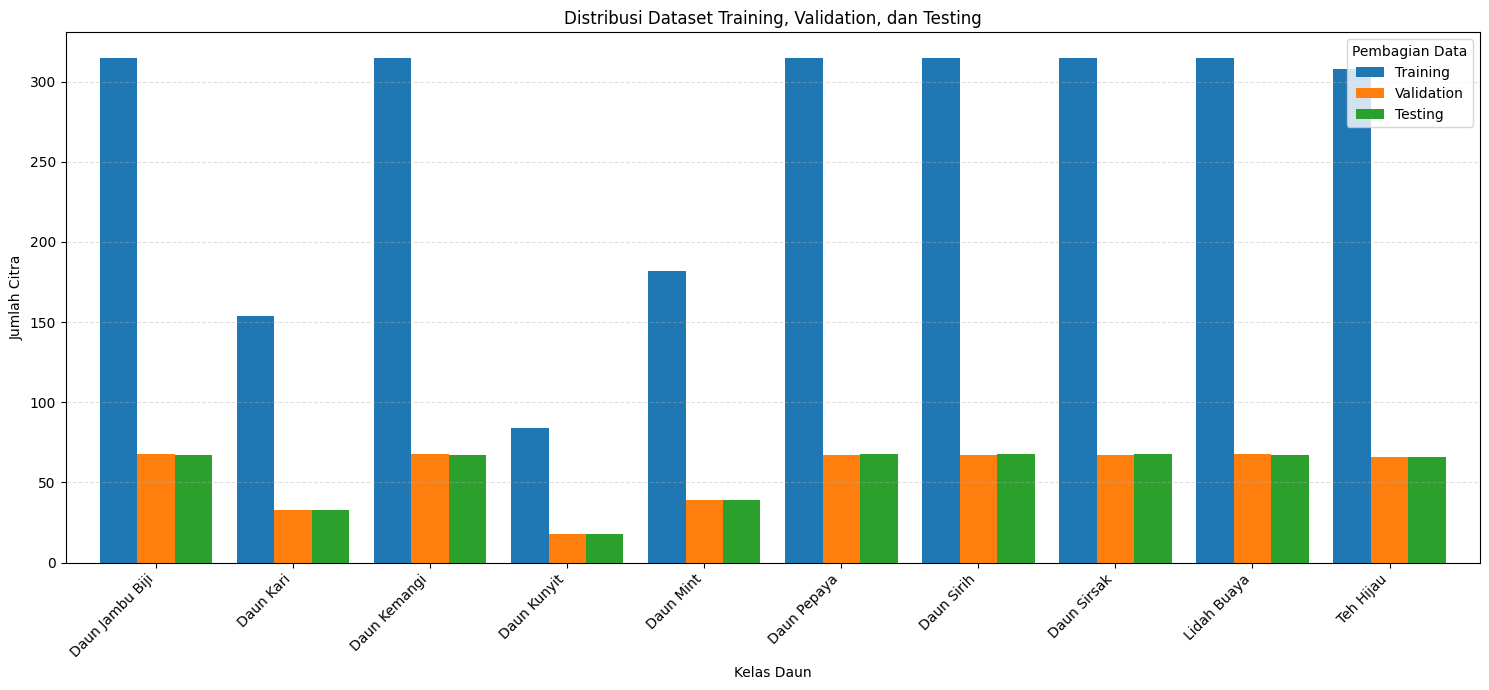

,Jumlah Citra
Training,2618
Validation,561
Testing,561


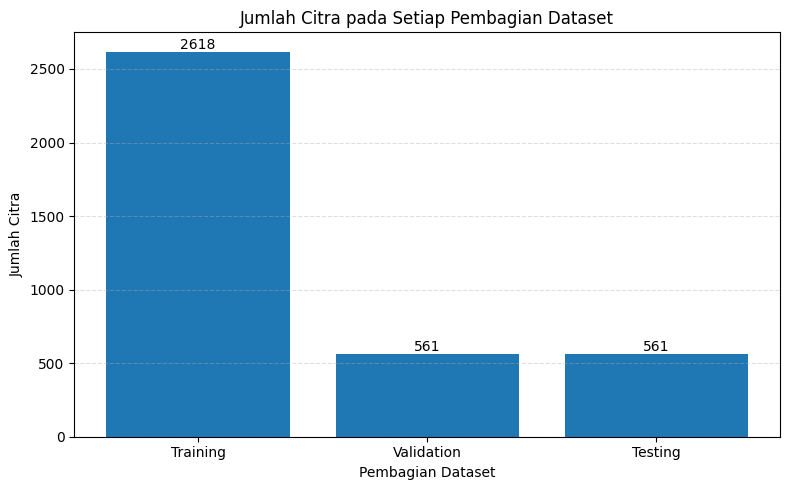

In [12]:
# ============================================================
# 8. DISTRIBUSI HASIL SPLIT
# ============================================================

distribusi_split = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Testing": test_df["label"].value_counts()
}).reindex(class_names).fillna(0).astype(int)

# Menambahkan total citra setiap kelas
distribusi_split["Total"] = distribusi_split[
    ["Training", "Validation", "Testing"]
].sum(axis=1)

display(distribusi_split)


# ============================================================
# GRAFIK DISTRIBUSI SETIAP KELAS
# ============================================================

distribusi_split[
    ["Training", "Validation", "Testing"]
].plot(
    kind="bar",
    figsize=(15, 7),
    width=0.82
)

plt.title(
    "Distribusi Dataset Training, Validation, dan Testing"
)
plt.xlabel("Kelas Daun")
plt.ylabel("Jumlah Citra")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Pembagian Data")
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)
plt.tight_layout()
plt.show()


# ============================================================
# MENGHITUNG TOTAL SETIAP SPLIT
# ============================================================

total_split = pd.Series({
    "Training": len(train_df),
    "Validation": len(val_df),
    "Testing": len(test_df)
})

display(
    total_split
    .rename("Jumlah Citra")
    .to_frame()
)


# ============================================================
# GRAFIK TOTAL SETIAP SPLIT
# ============================================================

plt.figure(figsize=(8, 5))

bars = plt.bar(
    total_split.index,
    total_split.values
)

plt.title(
    "Jumlah Citra pada Setiap Pembagian Dataset"
)
plt.xlabel("Pembagian Dataset")
plt.ylabel("Jumlah Citra")
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

for bar, jumlah in zip(
    bars,
    total_split.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(jumlah),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [13]:
# 9. TensorFlow Dataset
def load_and_preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)
    label = tf.cast(label, tf.int32)

    return image, label


def create_dataset(dataframe, shuffle=False):
    image_paths = dataframe["image_path"].astype(str).values
    labels = dataframe["label_index"].astype("int32").values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_dataset = create_dataset(train_df, shuffle=True)
val_dataset = create_dataset(val_df, shuffle=False)
test_dataset = create_dataset(test_df, shuffle=False)

print("Training dataset  :", train_dataset)
print("Validation dataset:", val_dataset)
print("Testing dataset   :", test_dataset)

for images, labels in train_dataset.take(1):
    print("\nShape citra :", images.shape)
    print("Shape label :", labels.shape)
    print("Nilai min   :", tf.reduce_min(images).numpy())
    print("Nilai max   :", tf.reduce_max(images).numpy())

Training dataset  : <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
Validation dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
Testing dataset   : <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

Shape citra : (32, 224, 224, 3)
Shape label : (32,)
Nilai min   : 0.0
Nilai max   : 255.0


In [15]:
# 10. Augmentasi baru
ROTATION_FACTOR = 20 / 360

data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(factor=ROTATION_FACTOR,fill_mode="nearest"),
        tf.keras.layers.RandomTranslation(height_factor=0.20,width_factor=0.20,fill_mode="nearest"),
        tf.keras.layers.RandomZoom(0.20,fill_mode="nearest")
    ],
    name="data_augmentation"
)


In [16]:
# 11. Model MobileNetV2
inputs = Input(
    shape=INPUT_SHAPE,
    name="input_image"
)

x = data_augmentation(inputs)

x = Rescaling(
    scale=1.0 / 127.5,
    offset=-1,
    name="mobilenetv2_preprocess"
)(x)

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=INPUT_SHAPE,
    name="mobilenetv2_base"
)

base_model.trainable = False
x = base_model(x, training=False)

x = GlobalAveragePooling2D(name="gap")(x)

x = Dense(
    256,
    activation="relu",
    kernel_regularizer=l2(0.001),
    name="classifier_dense"
)(x)

x = Dropout(0.4,name="classifier_dropout")(x)

outputs = Dense(
    num_classes,
    activation="softmax",
    name="predictions"
)(x)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="MobileNetV2_HerbalLeaf_NoClassWeight"
)

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Input model:", model.input_shape)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Input model: (None, 224, 224, 3)


Model: "MobileNetV2_HerbalLeaf_NoClassWeight"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_preprocess          │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_base (Functional)   │ (None, 7, 7, 1280)     │     2,257,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dense (Dense)        │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,588,490 (9.87 MB)

 Trainable params: 330,506 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [17]:
# =========================
# TRAIN TAHAP 1
# Feature Extraction
# =========================

base_model.trainable = False

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

SAVE_DIR = "/content/drive/MyDrive/skripsi_mobilenetv2"
os.makedirs(SAVE_DIR, exist_ok=True)

callbacks_tahap1 = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=7,
        restore_best_weights=True,
        mode="max",
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_accuracy",
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        mode="max",
        verbose=1
    ),
    ModelCheckpoint(
        os.path.join(SAVE_DIR, "best_mobilenetv2_tahap1.keras"),
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    )
]

history_tahap1 = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS_TAHAP1,
    callbacks=callbacks_tahap1
)


Epoch 1/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3481 - loss: 2.4954
Epoch 1: val_accuracy improved from None to 0.81996, saving model to /content/drive/MyDrive/skripsi_mobilenetv2/best_mobilenetv2_tahap1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/skripsi_mobilenetv2/best_mobilenetv2_tahap1.keras
82/82 ━━━━━━━━━━━━━━━━━━━━ 218s 3s/step - accuracy: 0.5141 - loss: 1.9588 - val_accuracy: 0.8200 - val_loss: 1.1755 - learning_rate: 1.0000e-04
Epoch 2/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7645 - loss: 1.2139
Epoch 2: val_accuracy improved from 0.81996 to 0.91979, saving model to /content/drive/MyDrive/skripsi_mobilenetv2/best_mobilenetv2_tahap1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/skripsi_mobilenetv2/best_mobilenetv2_tahap1.keras
82/82 ━━━━━━━━━━━━━━━━━━━━ 212s 3s/step - accuracy: 0.7792 - loss: 1.1551 - val_accuracy: 0.9198 - val_loss: 0.8301 - learning_rate: 1.0000e-04
Epoch 3/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2s

In [18]:
# Mengambil nilai accuracy dan loss terakhir
train_accuracy = history_tahap1.history['accuracy'][-1]
val_accuracy = history_tahap1.history['val_accuracy'][-1]

train_loss = history_tahap1.history['loss'][-1]
val_loss = history_tahap1.history['val_loss'][-1]

print("Training Accuracy   :", train_accuracy)
print("Validation Accuracy :", val_accuracy)

print("\nTraining Loss       :", train_loss)
print("Validation Loss     :", val_loss)

Training Accuracy   : 0.9694423079490662
Validation Accuracy : 0.9821746945381165

Training Loss       : 0.4572290778160095
Validation Loss     : 0.41640710830688477


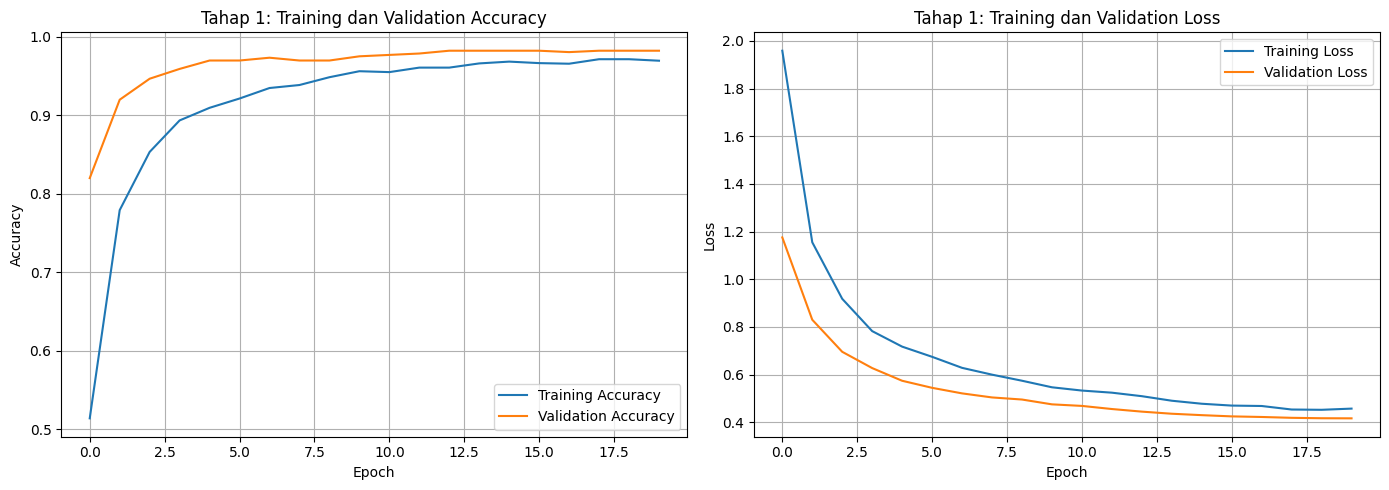

In [19]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_tahap1.history["accuracy"], label="Training Accuracy")
plt.plot(history_tahap1.history["val_accuracy"], label="Validation Accuracy")
plt.title("Tahap 1: Training dan Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_tahap1.history["loss"], label="Training Loss")
plt.plot(history_tahap1.history["val_loss"], label="Validation Loss")
plt.title("Tahap 1: Training dan Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [20]:
# =========================
# TRAIN TAHAP 2
# Fine-Tuning
# =========================

base_model.trainable = True

# Bekukan sebagian besar layer awal MobileNetV2
# Hanya 30 layer terakhir yang dilatih ulang.
for layer in base_model.layers[:-50]:
    layer.trainable = False

# BatchNormalization dibekukan agar fine-tuning lebih stabil pada dataset kecil
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_tahap2 = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=7,
        restore_best_weights=True,
        mode="max",
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_accuracy",
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        mode="max",
        verbose=1
    ),
    ModelCheckpoint(
        os.path.join(SAVE_DIR, "best_mobilenetv2_tahap2.keras"),
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    )
]

history_tahap2 = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS_TAHAP2,
    callbacks=callbacks_tahap2
)


Epoch 1/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9532 - loss: 0.5073
Epoch 1: val_accuracy improved from None to 0.98217, saving model to /content/drive/MyDrive/skripsi_mobilenetv2/best_mobilenetv2_tahap2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/skripsi_mobilenetv2/best_mobilenetv2_tahap2.keras
82/82 ━━━━━━━━━━━━━━━━━━━━ 274s 3s/step - accuracy: 0.9561 - loss: 0.4967 - val_accuracy: 0.9822 - val_loss: 0.4286 - learning_rate: 1.0000e-05
Epoch 2/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9715 - loss: 0.4599
Epoch 2: val_accuracy did not improve from 0.98217
82/82 ━━━━━━━━━━━━━━━━━━━━ 261s 3s/step - accuracy: 0.9710 - loss: 0.4611 - val_accuracy: 0.9822 - val_loss: 0.4258 - learning_rate: 1.0000e-05
Epoch 3/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9696 - loss: 0.4485
Epoch 3: val_accuracy improved from 0.98217 to 0.98752, saving model to /content/drive/MyDrive/skripsi_mobilenetv2/best_mobilenetv2_tahap2.keras

Epoch 3: finishe

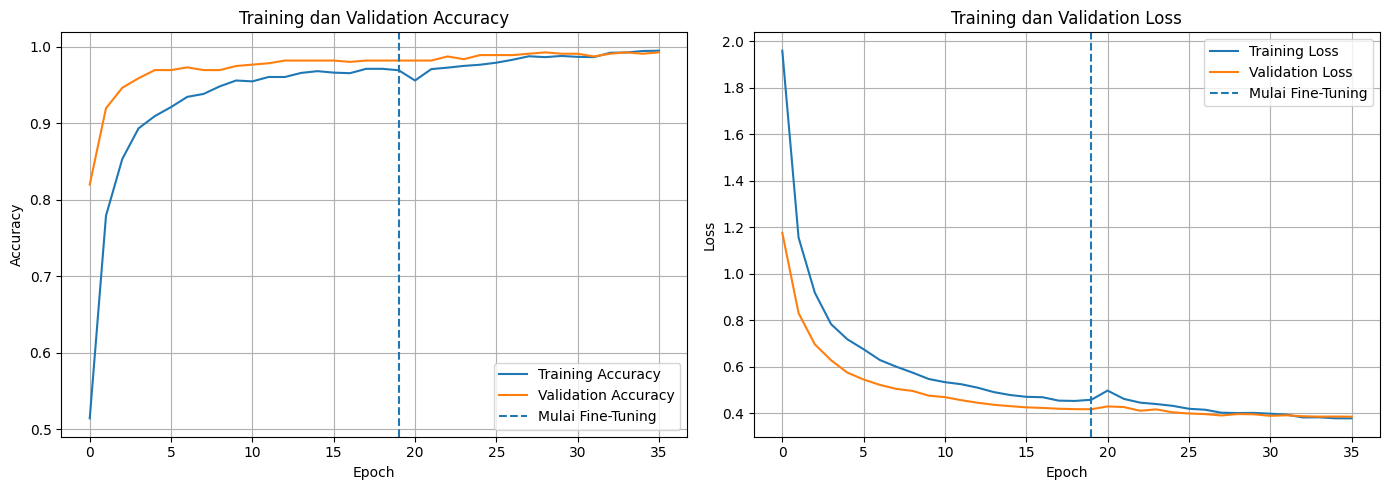

In [28]:
# 14. Grafik gabungan tahap 1 dan tahap 2
acc = (
    history_tahap1.history["accuracy"]
    + history_tahap2.history["accuracy"]
)

val_acc = (
    history_tahap1.history["val_accuracy"]
    + history_tahap2.history["val_accuracy"]
)

loss = (
    history_tahap1.history["loss"]
    + history_tahap2.history["loss"]
)

val_loss = (
    history_tahap1.history["val_loss"]
    + history_tahap2.history["val_loss"]
)

fine_tune_start = len(history_tahap1.history["accuracy"])

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(acc, label="Training Accuracy")
plt.plot(val_acc, label="Validation Accuracy")
plt.axvline(
    x=fine_tune_start - 1,
    linestyle="--",
    label="Mulai Fine-Tuning"
)
plt.title("Training dan Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.axvline(
    x=fine_tune_start - 1,
    linestyle="--",
    label="Mulai Fine-Tuning"
)
plt.title("Training dan Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [22]:
train_loss, train_accuracy = model.evaluate(train_dataset, verbose=0)
val_loss, val_accuracy = model.evaluate(val_dataset, verbose=0)
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=0)

result_df = pd.DataFrame({
    'Data': ['Training', 'Validation', 'Testing'],
    'Accuracy': [train_accuracy, val_accuracy, test_accuracy],
    'Loss': [train_loss, val_loss, test_loss]
})

result_df

,Data,Accuracy,Loss
0,Training,0.994652,0.377471
1,Validation,0.992870,0.395749
2,Testing,0.991087,0.392694


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Pastikan result_df tidak kosong
if result_df.empty:
    raise ValueError("result_df kosong, sehingga grafik tidak dapat dibuat.")

# Pastikan nilai Accuracy dan Loss berupa angka
result_df["Accuracy"] = pd.to_numeric(
    result_df["Accuracy"],
    errors="coerce"
)

result_df["Loss"] = pd.to_numeric(
    result_df["Loss"],
    errors="coerce"
)

# Periksa apakah ada nilai NaN
if result_df[["Accuracy", "Loss"]].isna().any().any():
    raise ValueError(
        "Terdapat nilai kosong atau bukan angka "
        "pada kolom Accuracy atau Loss."
    )

display(result_df)

,Data,Accuracy,Loss
0,Training,0.994652,0.377471
1,Validation,0.992870,0.395749
2,Testing,0.991087,0.392694


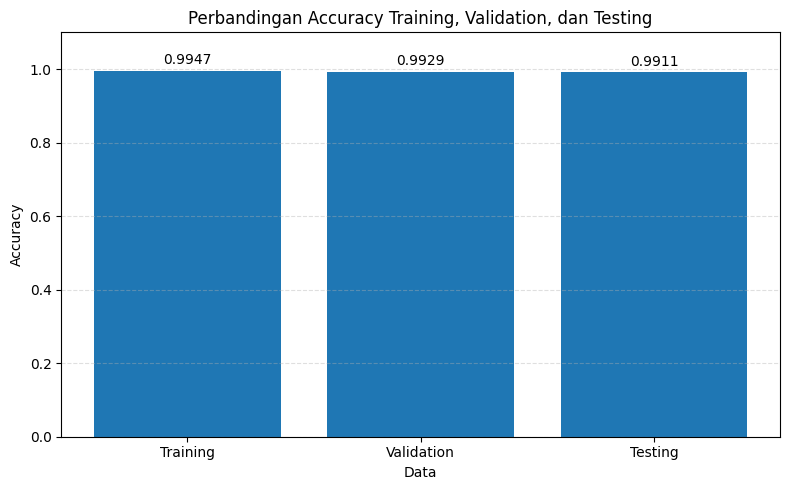

In [30]:
# ============================================================
# GRAFIK ACCURACY
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    result_df["Data"].astype(str),
    result_df["Accuracy"].astype(float)
)

ax.set_title(
    "Perbandingan Accuracy Training, Validation, dan Testing"
)
ax.set_xlabel("Data")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.1)
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

for bar, value in zip(
    bars,
    result_df["Accuracy"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        float(value) + 0.01,
        f"{float(value):.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

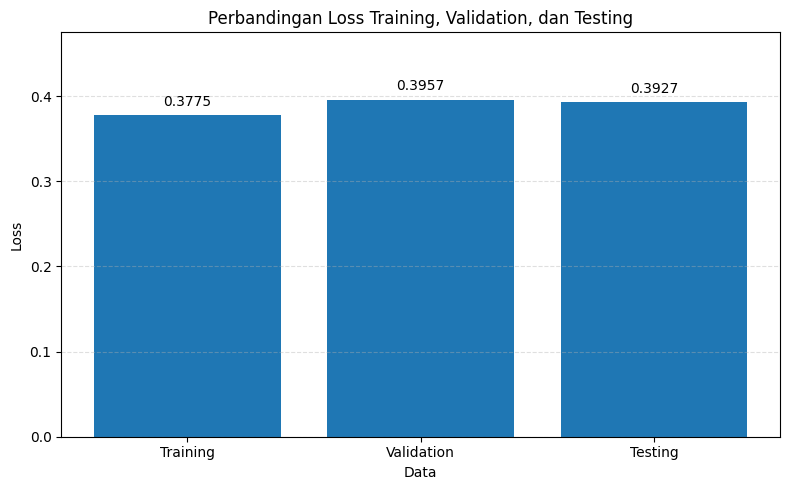

In [31]:
# ============================================================
# GRAFIK LOSS
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    result_df["Data"].astype(str),
    result_df["Loss"].astype(float)
)

ax.set_title(
    "Perbandingan Loss Training, Validation, dan Testing"
)
ax.set_xlabel("Data")
ax.set_ylabel("Loss")
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

nilai_loss_tertinggi = float(
    result_df["Loss"].max()
)

ax.set_ylim(
    0,
    nilai_loss_tertinggi * 1.20
)

for bar, value in zip(
    bars,
    result_df["Loss"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        float(value) + nilai_loss_tertinggi * 0.02,
        f"{float(value):.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [32]:
# ============================================================
# MENGAMBIL LABEL ASLI DAN LABEL PREDIKSI
# ============================================================

y_true = []
y_pred = []

for images, labels in test_dataset:

    predictions = model.predict(
        images,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(
        labels.numpy()
    )

    y_pred.extend(
        predicted_labels
    )

y_true = np.array(
    y_true,
    dtype=np.int32
)

y_pred = np.array(
    y_pred,
    dtype=np.int32
)

print("Jumlah label asli     :", len(y_true))
print("Jumlah label prediksi :", len(y_pred))
print("Contoh label asli     :", y_true[:10])
print("Contoh hasil prediksi :", y_pred[:10])

Jumlah label asli     : 561
Jumlah label prediksi : 561
Contoh label asli     : [5 4 5 8 8 1 5 6 7 9]
Contoh hasil prediksi : [5 4 5 8 8 1 5 6 7 9]


In [25]:
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)

                 precision    recall  f1-score   support

Daun Jambu Biji     1.0000    0.9851    0.9925        67
      Daun Kari     1.0000    1.0000    1.0000        33
   Daun Kemangi     0.9565    0.9851    0.9706        67
    Daun Kunyit     1.0000    1.0000    1.0000        18
      Daun Mint     1.0000    1.0000    1.0000        39
    Daun Pepaya     0.9855    1.0000    0.9927        68
     Daun Sirih     0.9855    1.0000    0.9927        68
    Daun Sirsak     1.0000    1.0000    1.0000        68
    Lidah Buaya     1.0000    1.0000    1.0000        67
      Teh Hijau     1.0000    0.9545    0.9767        66

       accuracy                         0.9911       561
      macro avg     0.9928    0.9925    0.9925       561
   weighted avg     0.9913    0.9911    0.9911       561



In [33]:
import os
import shutil

# Pastikan report berupa string
if not isinstance(report, str):
    report = str(report)

# Lokasi sementara di penyimpanan Colab
LOCAL_REPORT_PATH = (
    "/content/classification_report_mobilenetv2.txt"
)

# Lokasi akhir di Google Drive
REPORT_PATH = (
    "/content/drive/MyDrive/"
    "classification_report_mobilenetv2.txt"
)

# 1. Simpan terlebih dahulu secara lokal
with open(
    LOCAL_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

print("Berhasil disimpan sementara di:", LOCAL_REPORT_PATH)

# 2. Pastikan Google Drive tersedia
if not os.path.exists("/content/drive/MyDrive"):
    raise FileNotFoundError(
        "Google Drive belum terhubung atau koneksinya terputus."
    )

# 3. Salin file ke Google Drive
shutil.copy2(
    LOCAL_REPORT_PATH,
    REPORT_PATH
)

# 4. Periksa hasil penyimpanan
if os.path.exists(REPORT_PATH):
    print("Classification report tersimpan di:")
    print(REPORT_PATH)
    print(
        "Ukuran file:",
        os.path.getsize(REPORT_PATH),
        "byte"
    )
else:
    raise FileNotFoundError(
        "File gagal disalin ke Google Drive."
    )

Berhasil disimpan sementara di: /content/classification_report_mobilenetv2.txt
Classification report tersimpan di:
/content/drive/MyDrive/classification_report_mobilenetv2.txt
Ukuran file: 800 byte


In [34]:
import os

REPORT_PATH = (
    "/content/drive/MyDrive/"
    "classification_report_mobilenetv2.txt"
)

print("File ditemukan:", os.path.exists(REPORT_PATH))

if os.path.exists(REPORT_PATH):
    print("Ukuran file:", os.path.getsize(REPORT_PATH), "byte")

File ditemukan: True
Ukuran file: 800 byte


In [35]:
with open(
    REPORT_PATH,
    "r",
    encoding="utf-8"
) as file:
    isi_report = file.read()

print(isi_report)

                 precision    recall  f1-score   support

Daun Jambu Biji     1.0000    0.9851    0.9925        67
      Daun Kari     1.0000    1.0000    1.0000        33
   Daun Kemangi     0.9565    0.9851    0.9706        67
    Daun Kunyit     1.0000    1.0000    1.0000        18
      Daun Mint     1.0000    1.0000    1.0000        39
    Daun Pepaya     0.9855    1.0000    0.9927        68
     Daun Sirih     0.9855    1.0000    0.9927        68
    Daun Sirsak     1.0000    1.0000    1.0000        68
    Lidah Buaya     1.0000    1.0000    1.0000        67
      Teh Hijau     1.0000    0.9545    0.9767        66

       accuracy                         0.9911       561
      macro avg     0.9928    0.9925    0.9925       561
   weighted avg     0.9913    0.9911    0.9911       561



In [36]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Pastikan format label benar
y_true = np.asarray(
    y_true,
    dtype=np.int32
).reshape(-1)

y_pred = np.asarray(
    y_pred,
    dtype=np.int32
).reshape(-1)

print("Jumlah label asli     :", len(y_true))
print("Jumlah label prediksi :", len(y_pred))

if len(y_true) == 0:
    raise ValueError("y_true masih kosong.")

if len(y_true) != len(y_pred):
    raise ValueError(
        "Jumlah y_true dan y_pred tidak sama."
    )

# Menghitung confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

print("Confusion matrix berhasil dihitung:")
print(cm)

Jumlah label asli     : 561
Jumlah label prediksi : 561
Confusion matrix berhasil dihitung:
[[66  0  1  0  0  0  0  0  0  0]
 [ 0 33  0  0  0  0  0  0  0  0]
 [ 0  0 66  0  0  1  0  0  0  0]
 [ 0  0  0 18  0  0  0  0  0  0]
 [ 0  0  0  0 39  0  0  0  0  0]
 [ 0  0  0  0  0 68  0  0  0  0]
 [ 0  0  0  0  0  0 68  0  0  0]
 [ 0  0  0  0  0  0  0 68  0  0]
 [ 0  0  0  0  0  0  0  0 67  0]
 [ 0  0  2  0  0  0  1  0  0 63]]


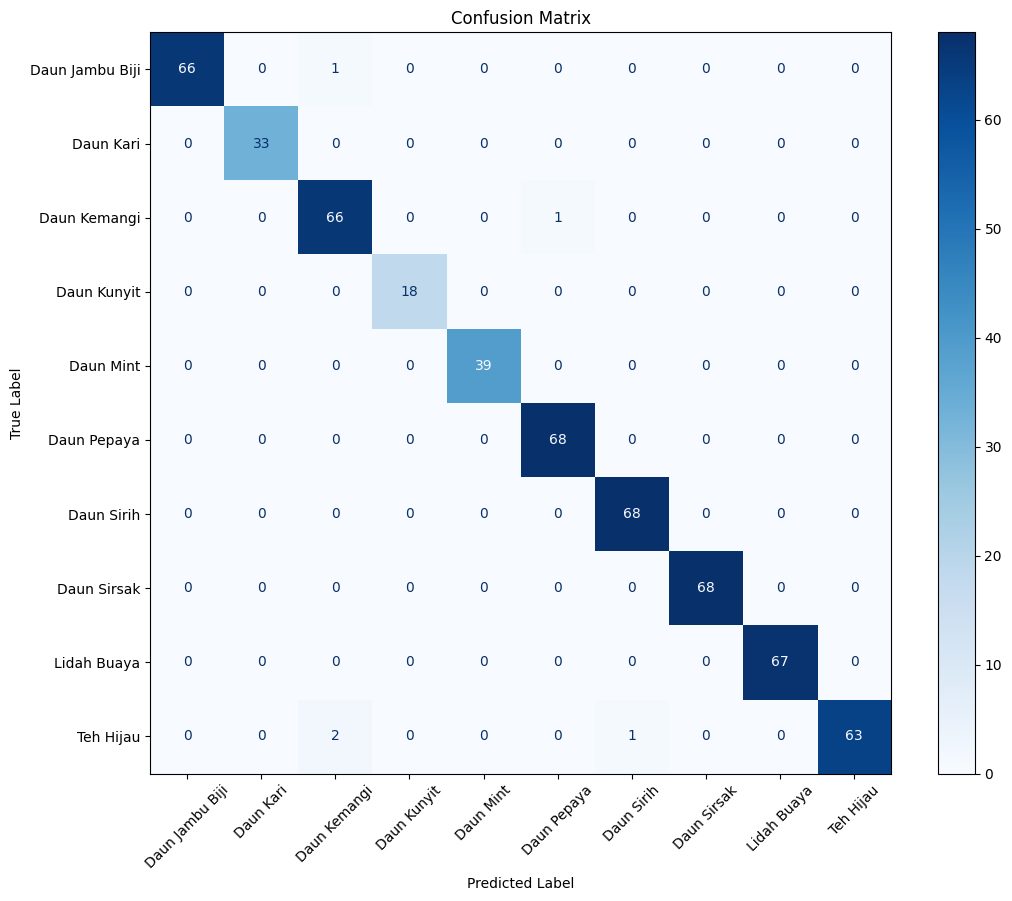

In [37]:
plt.close("all")

fig, ax = plt.subplots(
    figsize=(11, 9)
)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display_cm.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=True
)

ax.set_title("Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()
plt.close(fig)

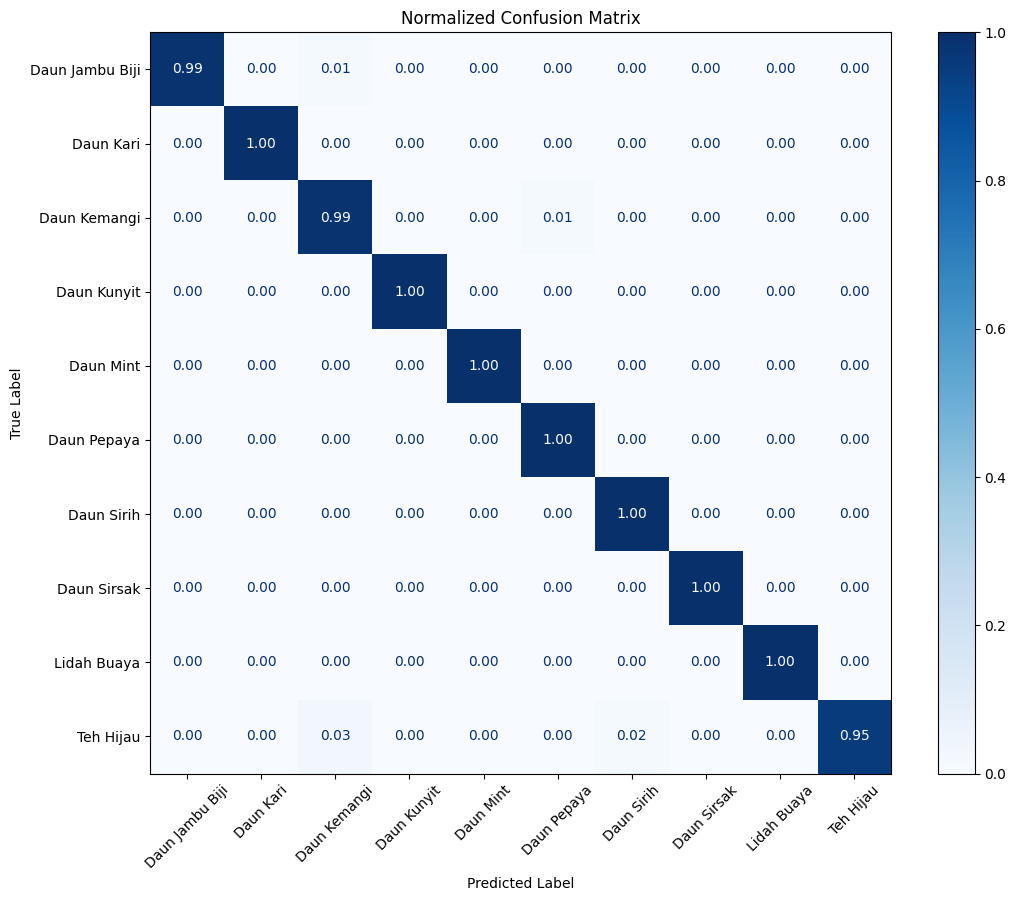

In [39]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

plt.close("all")

fig, ax = plt.subplots(figsize=(11, 9))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,

    # Urutan indeks seluruh kelas
    labels=np.arange(len(class_names)),

    # Nama kelas yang ditampilkan
    display_labels=class_names,

    # Normalisasi berdasarkan jumlah data aktual setiap kelas
    normalize="true",

    cmap="Blues",
    values_format=".2f",
    xticks_rotation=45,
    colorbar=True,
    ax=ax
)

ax.set_title("Normalized Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()

In [40]:
for i, layer in enumerate(model.layers):
    print(i, layer.name, type(layer))

0 input_image <class 'keras.src.layers.core.input_layer.InputLayer'>
1 data_augmentation <class 'keras.src.models.sequential.Sequential'>
2 mobilenetv2_preprocess <class 'keras.src.layers.preprocessing.rescaling.Rescaling'>
3 mobilenetv2_base <class 'keras.src.models.functional.Functional'>
4 gap <class 'keras.src.layers.pooling.global_average_pooling2d.GlobalAveragePooling2D'>
5 classifier_dense <class 'keras.src.layers.core.dense.Dense'>
6 classifier_dropout <class 'keras.src.layers.regularization.dropout.Dropout'>
7 predictions <class 'keras.src.layers.core.dense.Dense'>


In [41]:
# Cek layer konvolusi terakhir pada base model MobileNetV2.
last_conv_layer_name = "out_relu"

if last_conv_layer_name in [layer.name for layer in base_model.layers]:
    print("Layer ditemukan:", last_conv_layer_name)
else:
    raise ValueError(
        f"Layer {last_conv_layer_name} tidak ditemukan pada base_model."
    )

Layer ditemukan: out_relu


In [58]:
import cv2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
def build_gradcam_models(model, base_model, last_conv_layer_name="out_relu"):
    """
    Membuat dua model bantu untuk Grad-CAM:
    1. last_conv_model: input MobileNetV2 -> output layer konvolusi terakhir dan output base model.
    2. classifier_model: output base model -> prediksi kelas.
    """
    last_conv_layer = base_model.get_layer(last_conv_layer_name)

    last_conv_model = tf.keras.models.Model(
        inputs=base_model.input,
        outputs=[last_conv_layer.output, base_model.output],
        name="last_conv_model"
    )

    classifier_input = Input(shape=base_model.output.shape[1:], name="classifier_input")
    x = model.get_layer("gap")(classifier_input)
    x = model.get_layer("classifier_dense")(x)
    x = model.get_layer("classifier_dropout")(x, training=False)
    classifier_output = model.get_layer("predictions")(x)

    classifier_model = tf.keras.models.Model(
        inputs=classifier_input,
        outputs=classifier_output,
        name="classifier_model"
    )

    return last_conv_model, classifier_model


def make_gradcam_heatmap(img_array, last_conv_model, classifier_model, pred_index=None):
    """
    img_array harus berupa batch citra mentah skala 0-255 dengan shape (1, 224, 224, 3).
    """
    img_array = tf.cast(img_array, tf.float32)

    # Samakan preprocessing dengan MobileNetV2
    preprocessed_img = preprocess_input(img_array)

    with tf.GradientTape() as tape:
        conv_outputs, base_outputs = last_conv_model(preprocessed_img)
        tape.watch(conv_outputs)

        predictions = classifier_model(base_outputs)

        if pred_index is None:
            pred_index = tf.argmax(predictions[0])

        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)

    if grads is None:
        raise ValueError("Gradient tidak terbentuk. Periksa last_conv_layer_name dan struktur model.")

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0)
    max_value = tf.reduce_max(heatmap)

    if max_value == 0:
        return heatmap.numpy()

    heatmap = heatmap / max_value
    return heatmap.numpy()


In [59]:
print("Base model:", base_model.name)
print("Layer Grad-CAM:", base_model.get_layer("out_relu").name)

Base model: mobilenetv2_base
Layer Grad-CAM: out_relu


In [60]:
from tensorflow.keras.utils import load_img, img_to_array
def display_gradcam(
    image_path,
    model,
    last_conv_model,
    classifier_model,
    alpha=0.4
):
    # Pastikan file tersedia
    if not os.path.exists(image_path):
        raise FileNotFoundError(
            f"Citra tidak ditemukan:\n{image_path}"
        )

    # Membaca citra
    original_img = load_img(
        image_path,
        target_size=(IMG_SIZE, IMG_SIZE)
    )

    original_array = img_to_array(
        original_img
    ).astype(np.uint8)

    # Input model berupa float32 dengan rentang 0-255
    img_array = np.expand_dims(
        original_array.astype(np.float32),
        axis=0
    )

    # Prediksi
    predictions = model.predict(
        img_array,
        verbose=0
    )

    pred_index = int(
        np.argmax(predictions[0])
    )

    pred_label = index_to_label[
        pred_index
    ]

    confidence = float(
        predictions[0][pred_index]
    )

    # Membuat heatmap
    heatmap = make_gradcam_heatmap(
        img_array,
        last_conv_model,
        classifier_model,
        pred_index=pred_index
    )

    heatmap = np.nan_to_num(
        heatmap,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    heatmap = cv2.resize(
        heatmap,
        (IMG_SIZE, IMG_SIZE)
    )

    heatmap = np.clip(
        heatmap,
        0,
        1
    )

    heatmap_uint8 = np.uint8(
        255 * heatmap
    )

    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    superimposed_img = cv2.addWeighted(
        original_array,
        1 - alpha,
        heatmap_color,
        alpha,
        0
    )

    # Menampilkan hasil
    plt.close("all")

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(14, 5)
    )

    axes[0].imshow(original_array)
    axes[0].set_title("Citra Asli")
    axes[0].axis("off")

    axes[1].imshow(
        heatmap,
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[1].set_title("Heatmap Grad-CAM")
    axes[1].axis("off")

    axes[2].imshow(superimposed_img)
    axes[2].set_title(
        f"Prediksi: {pred_label}\n"
        f"Confidence: {confidence:.4f}"
    )
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

    return {
        "predicted_index": pred_index,
        "predicted_label": pred_label,
        "confidence": confidence,
        "heatmap_max": float(np.max(heatmap))
    }

In [61]:
last_conv_layer_name = "out_relu"

last_conv_model, classifier_model = build_gradcam_models(
    model=model,
    base_model=base_model,
    last_conv_layer_name=last_conv_layer_name
)

print("Model Grad-CAM berhasil dibuat menggunakan layer:", last_conv_layer_name)


Model Grad-CAM berhasil dibuat menggunakan layer: out_relu


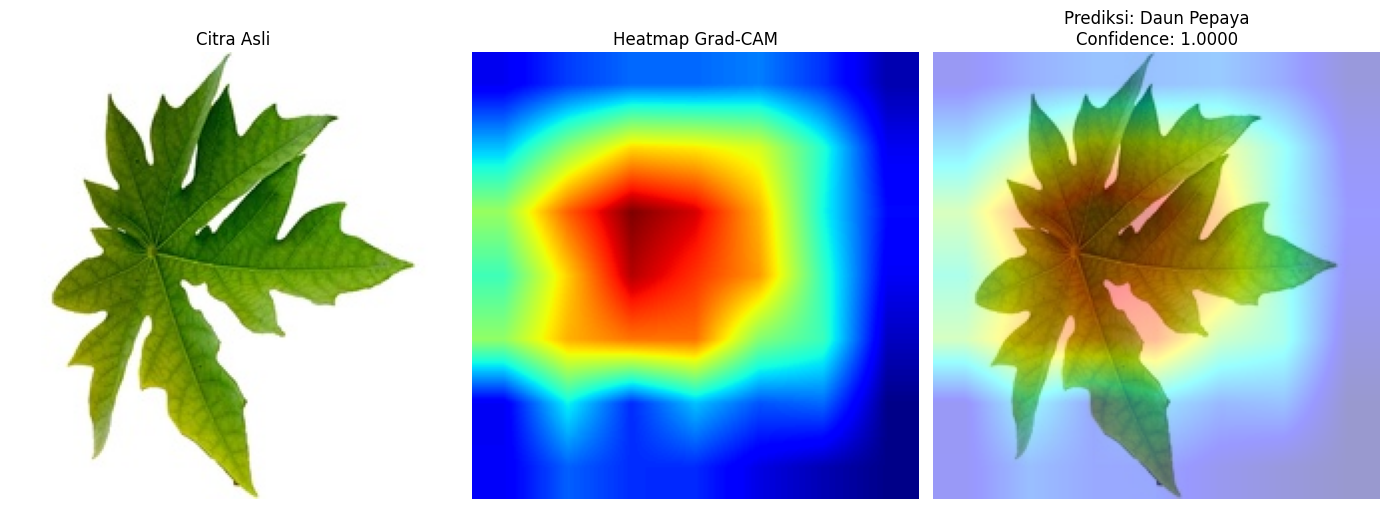

{'predicted_index': 5, 'predicted_label': 'Daun Pepaya', 'confidence': 0.999954342842102, 'heatmap_max': 0.9980701804161072}


In [62]:
sample_image_path = test_df.iloc[0]["image_path"]

hasil_gradcam = display_gradcam(
    sample_image_path,
    model,
    last_conv_model,
    classifier_model
)

print(hasil_gradcam)

Label asli: Daun Pepaya
Path: /content/drive/MyDrive/DATASETSPLIT/test/Daun Pepaya/Daun_Pepaya_00000.jpg


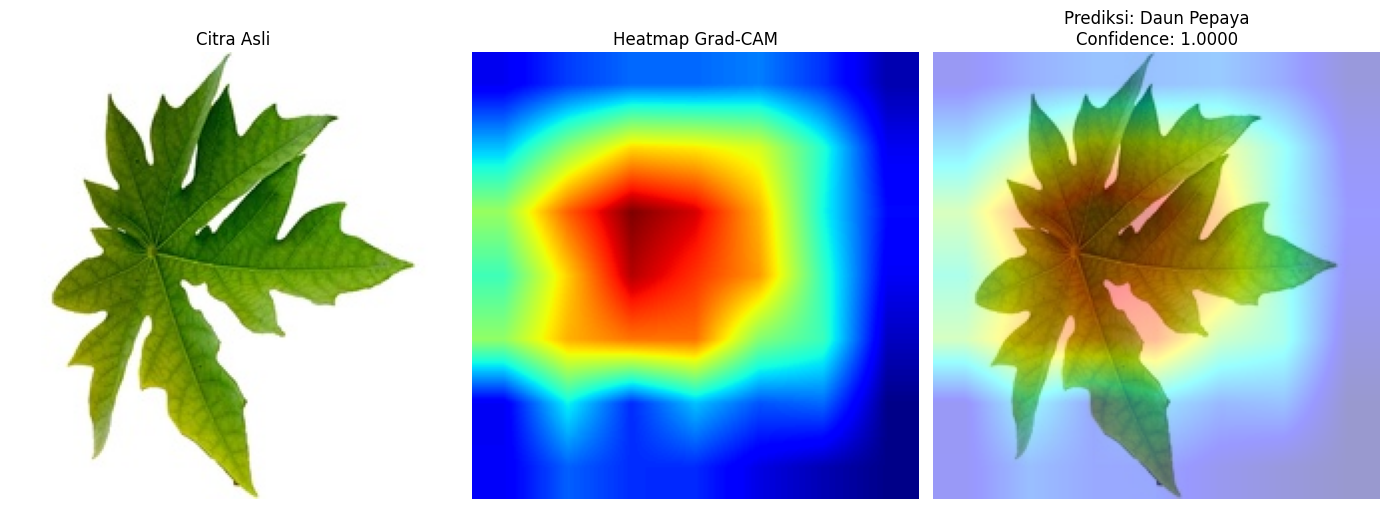

{'predicted_index': 5,
 'predicted_label': 'Daun Pepaya',
 'confidence': 0.999954342842102,
 'heatmap_max': 0.9980701804161072}

In [63]:
sample_image_path = test_df.iloc[0]["image_path"]
sample_true_label = test_df.iloc[0]["label"]

print("Label asli:", sample_true_label)
print("Path:", sample_image_path)

display_gradcam(
    sample_image_path,
    model,
    last_conv_model,
    classifier_model
)


Jumlah kelas: 10


/tmp/ipykernel_15312/272735110.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(1, random_state=42))


,label,image_path
0,Daun Jambu Biji,/content/drive/MyDrive/DATASETSPLIT/test/Daun ...
1,Daun Kari,/content/drive/MyDrive/DATASETSPLIT/test/Daun ...
2,Daun Kemangi,/content/drive/MyDrive/DATASETSPLIT/test/Daun ...
3,Daun Kunyit,/content/drive/MyDrive/DATASETSPLIT/test/Daun ...
4,Daun Mint,/content/drive/MyDrive/DATASETSPLIT/test/Daun ...
5,Daun Pepaya,/content/drive/MyDrive/DATASETSPLIT/test/Daun ...
6,Daun Sirih,/content/drive/MyDrive/DATASETSPLIT/test/Daun ...
7,Daun Sirsak,/content/drive/MyDrive/DATASETSPLIT/test/Daun ...
8,Lidah Buaya,/content/drive/MyDrive/DATASETSPLIT/test/Lidah...
9,Teh Hijau,/content/drive/MyDrive/DATASETSPLIT/test/Teh H...


Kelas ke-1
Label asli: Daun Jambu Biji
Path: /content/drive/MyDrive/DATASETSPLIT/test/Daun Jambu Biji/Daun_Jambu_Biji_00322.jpg


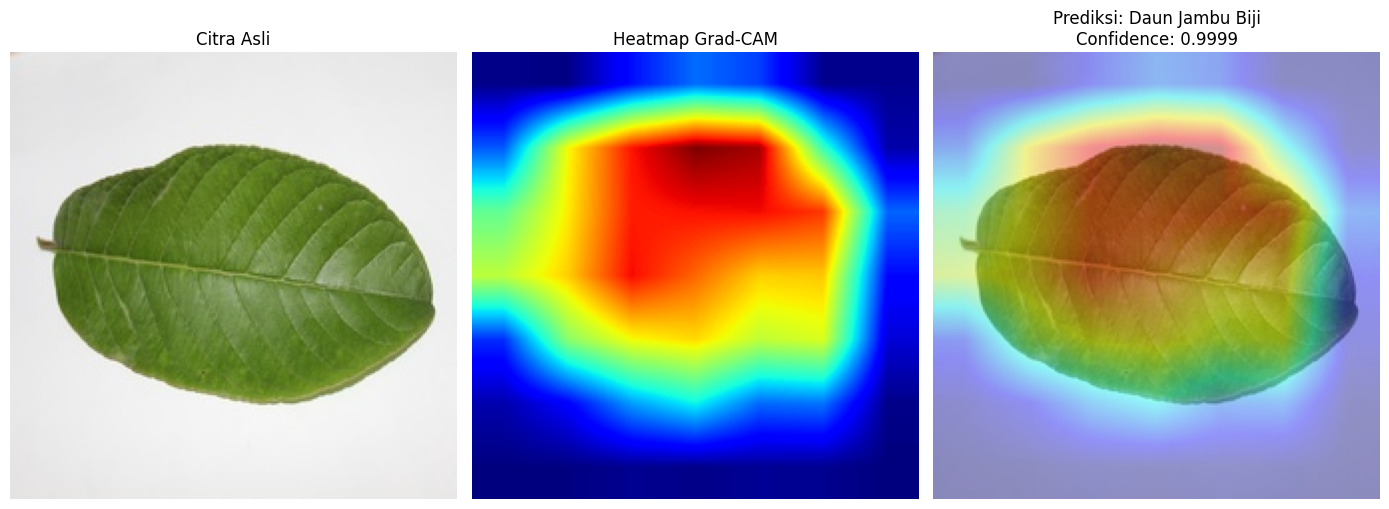

Kelas ke-2
Label asli: Daun Kari
Path: /content/drive/MyDrive/DATASETSPLIT/test/Daun Kari/Daun_Kari_00528.jpg


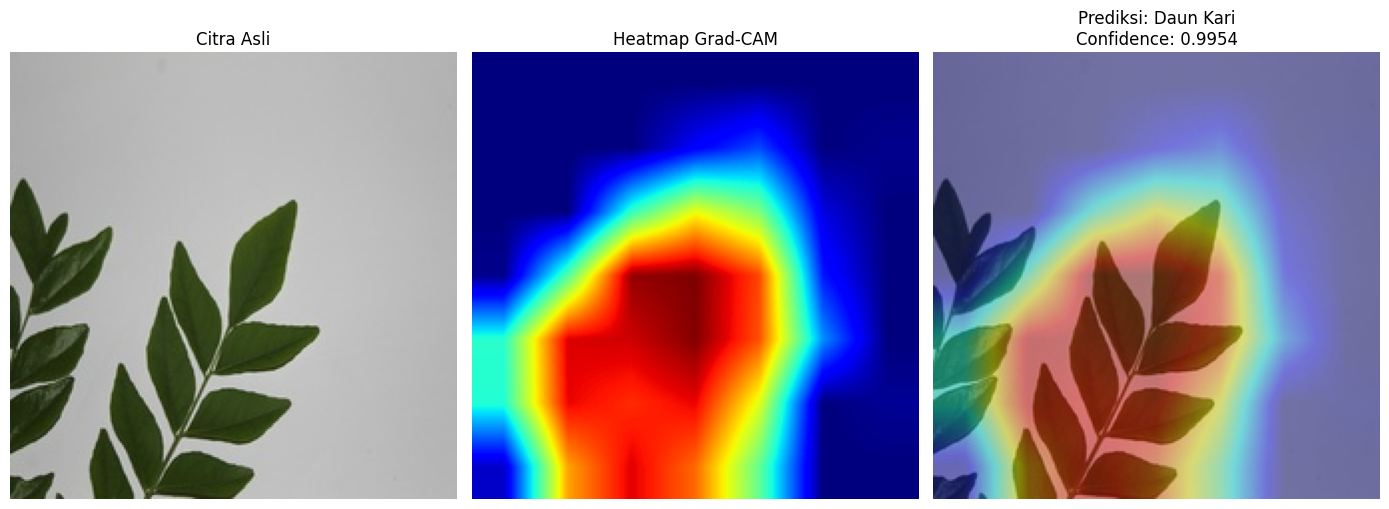

Kelas ke-3
Label asli: Daun Kemangi
Path: /content/drive/MyDrive/DATASETSPLIT/test/Daun Kemangi/Daun_Kemangi_00278.jpg


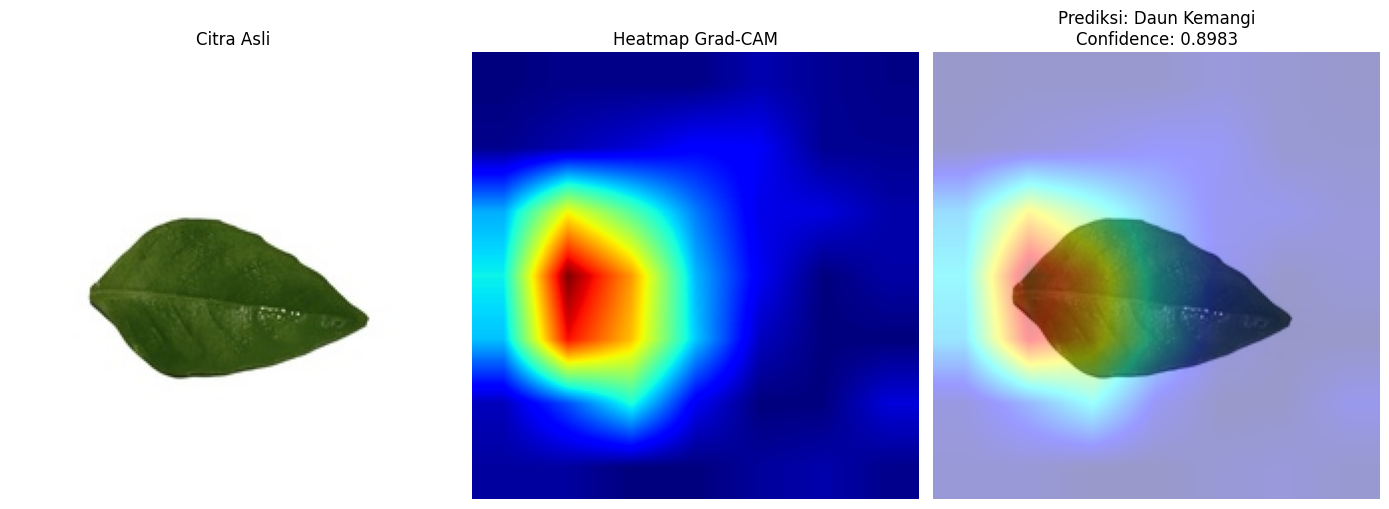

Kelas ke-4
Label asli: Daun Kunyit
Path: /content/drive/MyDrive/DATASETSPLIT/test/Daun Kunyit/Daun_Kunyit_00033.jpg


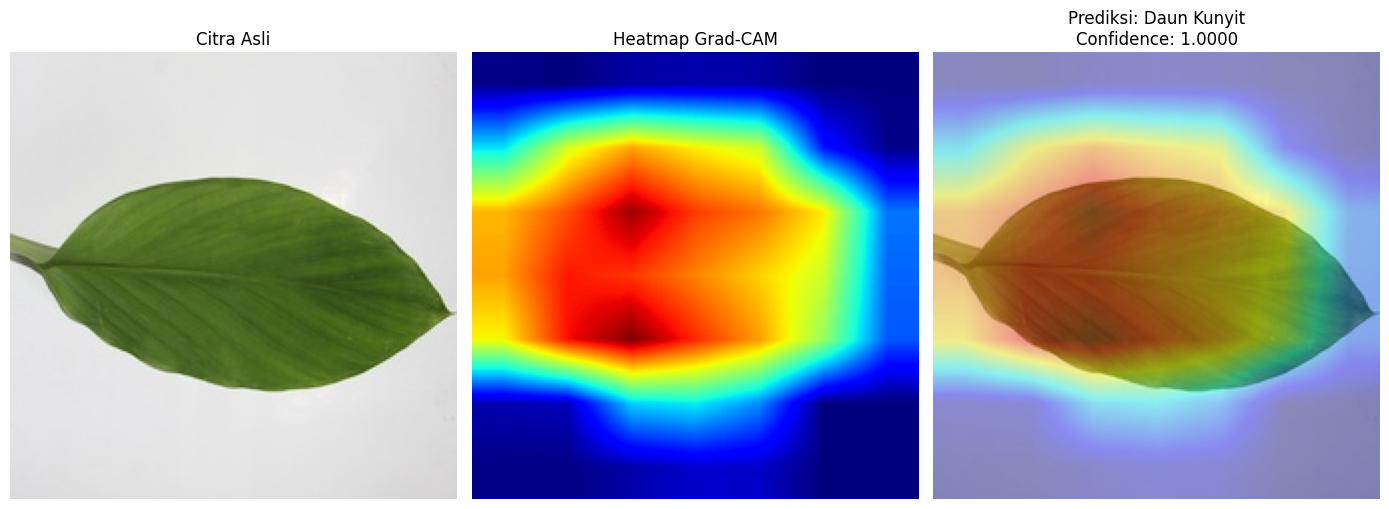

Kelas ke-5
Label asli: Daun Mint
Path: /content/drive/MyDrive/DATASETSPLIT/test/Daun Mint/Daun_Mint_00479.jpg


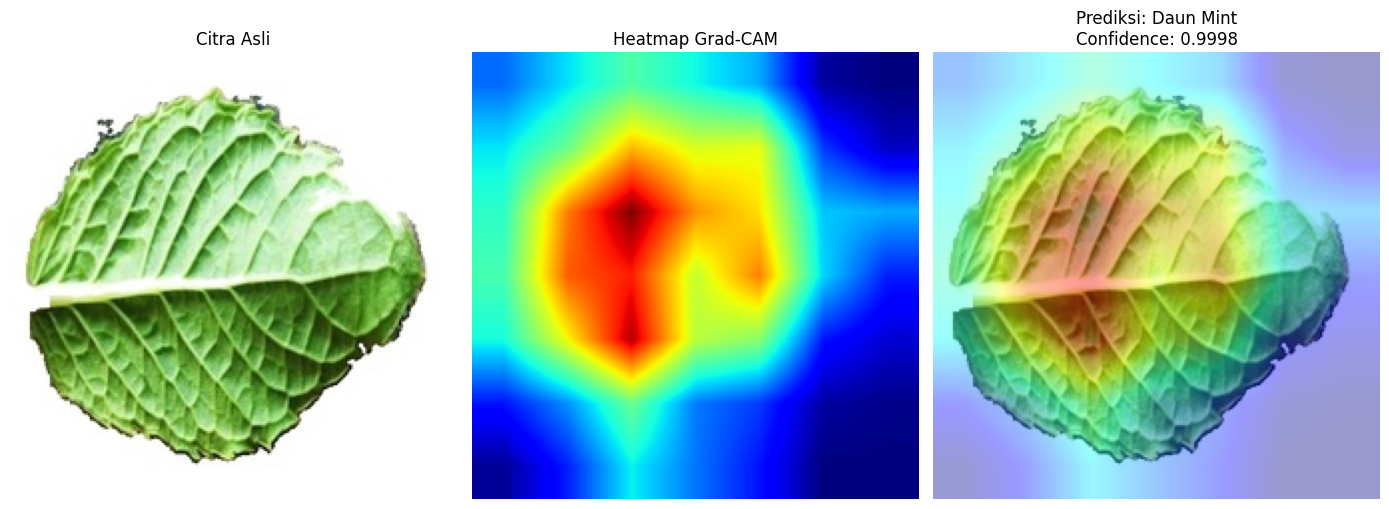

Kelas ke-6
Label asli: Daun Pepaya
Path: /content/drive/MyDrive/DATASETSPLIT/test/Daun Pepaya/Daun_Pepaya_00354.jpg


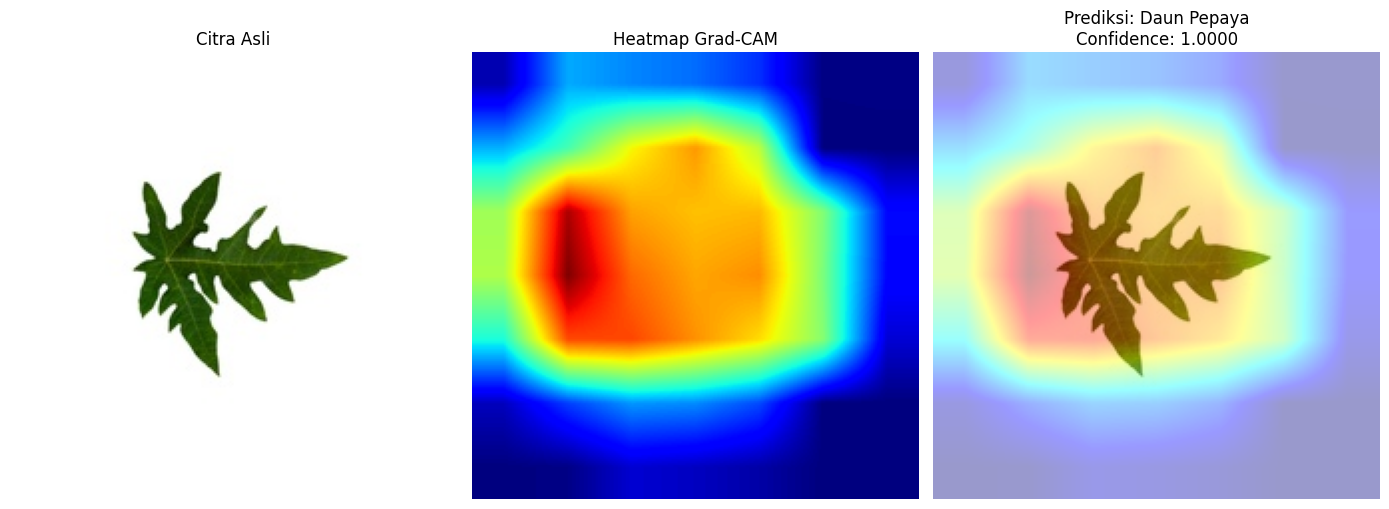

Kelas ke-7
Label asli: Daun Sirih
Path: /content/drive/MyDrive/DATASETSPLIT/test/Daun Sirih/Daun_Sirih_00375.jpg


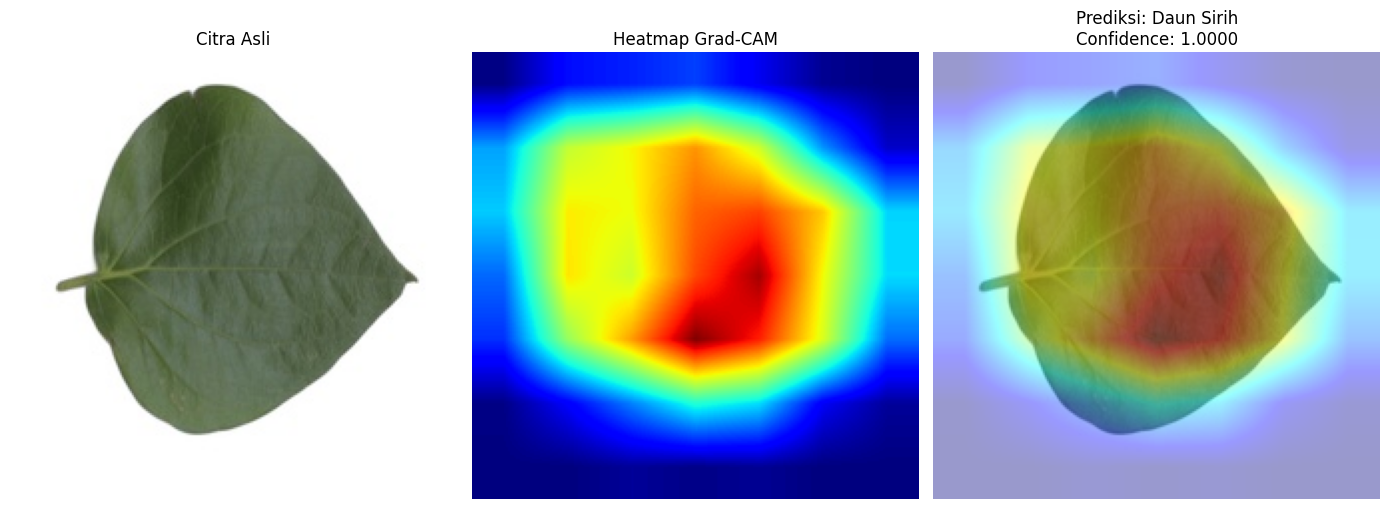

Kelas ke-8
Label asli: Daun Sirsak
Path: /content/drive/MyDrive/DATASETSPLIT/test/Daun Sirsak/Daun_Sirsak_00373.jpg


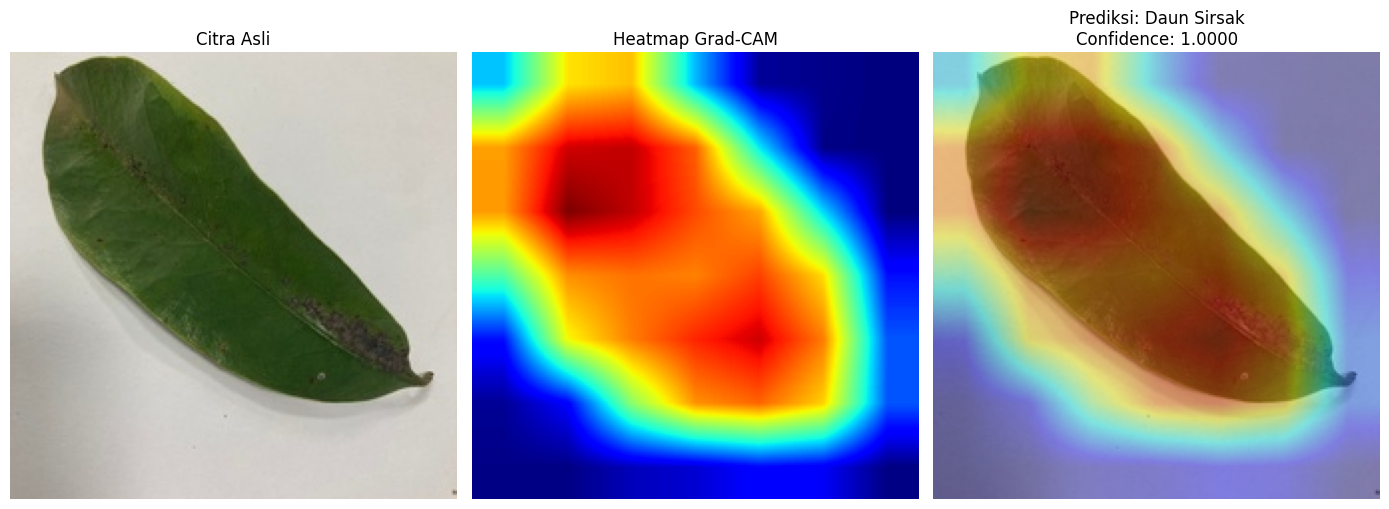

Kelas ke-9
Label asli: Lidah Buaya
Path: /content/drive/MyDrive/DATASETSPLIT/test/Lidah Buaya/Lidah_Buaya_00320.jpg


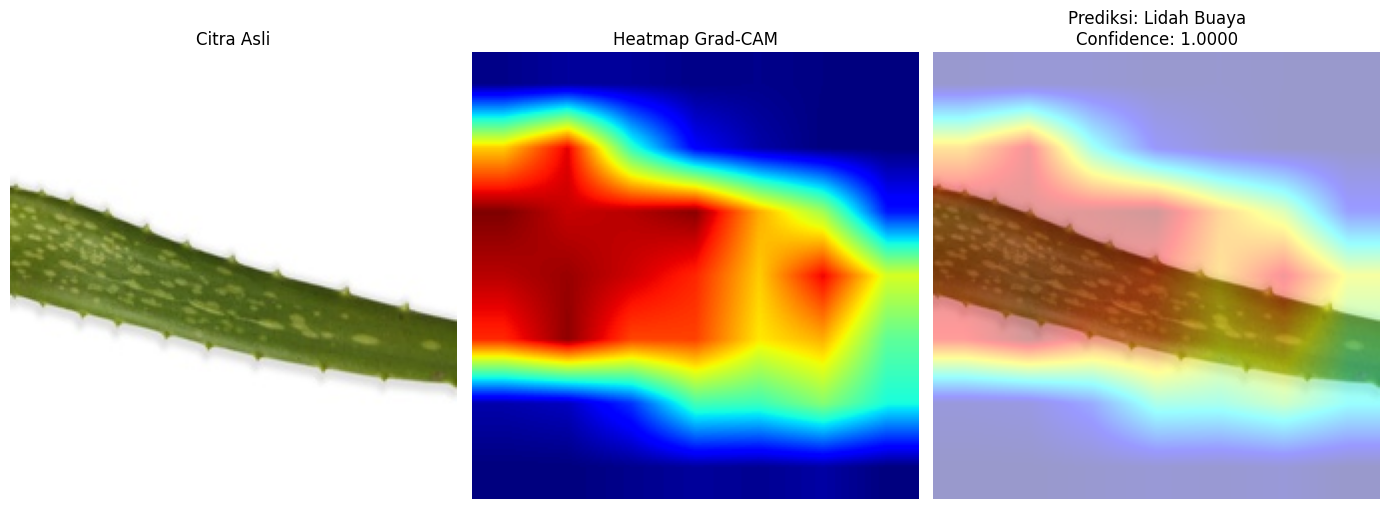

Kelas ke-10
Label asli: Teh Hijau
Path: /content/drive/MyDrive/DATASETSPLIT/test/Teh Hijau/Teh_Hijau_00478.jpg


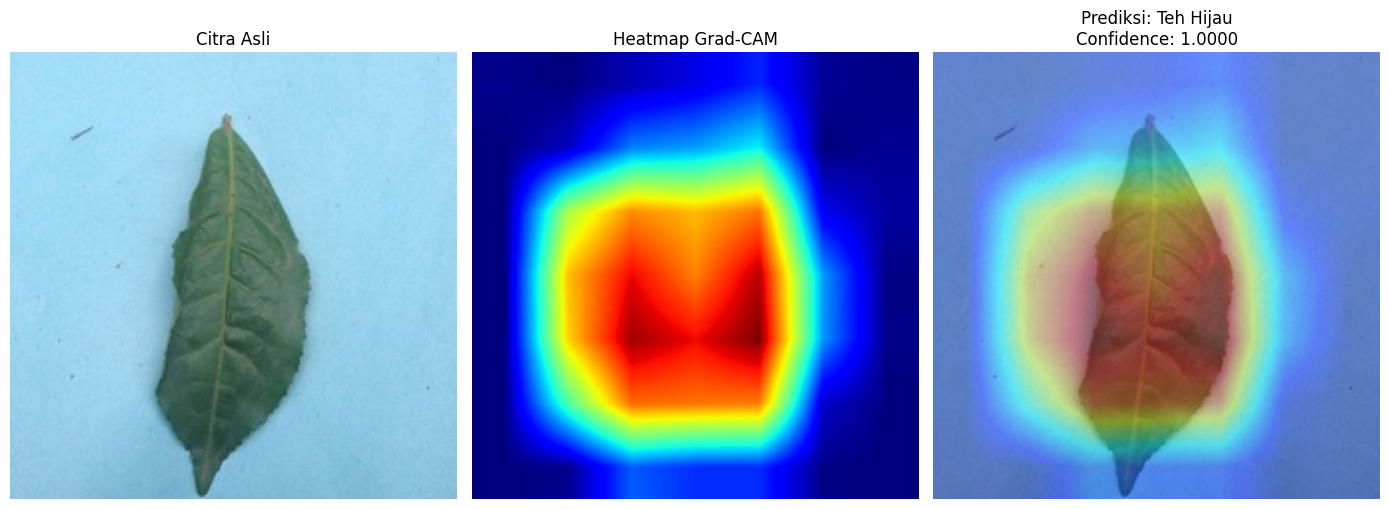

In [64]:
# Ambil 1 sample acak dari setiap kelas pada data testing
sample_per_class = (
    test_df
    .groupby("label", group_keys=False)
    .apply(lambda x: x.sample(1, random_state=42))
    .reset_index(drop=True)
)

print("Jumlah kelas:", len(sample_per_class))
display(sample_per_class[["label", "image_path"]])

for idx, row in sample_per_class.iterrows():
    sample_image_path = row["image_path"]
    sample_true_label = row["label"]

    print("=" * 80)
    print(f"Kelas ke-{idx+1}")
    print("Label asli:", sample_true_label)
    print("Path:", sample_image_path)

    display_gradcam(
        sample_image_path,
        model,
        last_conv_model,
        classifier_model
    )

In [65]:
FINAL_MODEL_PATH = os.path.join(SAVE_DIR, "final_model_mobilenetv2_gradcam.keras")

model.save(FINAL_MODEL_PATH)

print("Model akhir tersimpan di:", FINAL_MODEL_PATH)

Model akhir tersimpan di: /content/drive/MyDrive/skripsi_mobilenetv2/final_model_mobilenetv2_gradcam.keras


In [66]:
loaded_model = tf.keras.models.load_model(FINAL_MODEL_PATH)

loaded_model.summary()

Model: "MobileNetV2_HerbalLeaf_NoClassWeight"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_preprocess          │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_base (Functional)   │ (None, 7, 7, 1280)     │     2,257,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dense (Dense)        │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,918,368 (26.39 MB)

 Trainable params: 2,164,938 (8.26 MB)

 Non-trainable params: 423,552 (1.62 MB)

 Optimizer params: 4,329,878 (16.52 MB)

## Catatan

- Jangan tambahkan `class_weight` pada `model.fit()`.
- Augmentasi hanya aktif saat training.
- Data validation dan testing tidak diaugmentasi.
- TFLite Float32 menerima citra RGB 224×224 dengan rentang piksel 0–255 karena normalisasi berada di dalam model.
- Ubah `DATASET_PATH` sebelum menjalankan notebook.